# Étape 2 — Préparation et analyse exploratoire des données (EDA)

**Objectif :** comprendre les données avant de modéliser, et préparer des features sans fuite d'information.

**Règles suivies dans ce notebook**
1. Le découpage train / validation / test est **chronologique** et fait **avant** tout prétraitement.
2. Les statistiques qui guident nos choix (corrélations, distributions, stationnarité) sont calculées sur le **train uniquement**.
3. La période de **test n'est jamais analysée** ici : elle reste intacte jusqu'à l'évaluation finale (étape 8).

Toutes les figures sont enregistrées dans `reports/figures/` pour le rapport et les slides.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from scipy import stats
from src.config import load_config
from src.data import prepare
from src import eda

cfg = load_config()
FIG = ROOT / cfg["paths"]["figures"]
PROC = ROOT / cfg["paths"]["processed"]

# Lance la préparation complète (nettoyage, découpage, features)
prepare.main()

prices = pd.read_csv(PROC / "prices_clean.csv", index_col=0, parse_dates=True)
returns = pd.read_csv(PROC / "returns.csv", index_col=0, parse_dates=True)
macro = pd.read_csv(PROC / "macro_aligned.csv", index_col=0, parse_dates=True)
report = json.load(open(PROC / "preparation_report.json", encoding="utf-8"))

train_end, val_end = cfg["split"]["train_end"], cfg["split"]["val_end"]
prices_train, returns_train = prices.loc[:train_end], returns.loc[:train_end]

Matplotlib is building the font cache; this may take a moment.


Période commune : 2012-05-18 -> 2025-12-30 (3424 jours, 25 actifs)
  train : 2013-05-21 -> 2019-11-29  (39480 lignes)
  val   : 2020-01-02 -> 2021-12-01  (11616 lignes)
  test  : 2022-01-03 -> 2025-11-28  (23544 lignes)
Fichiers écrits dans /Users/houdie/Desktop/portfolio-multi-agent/data/processed


## 2.1 Qualité des données

On regarde les valeurs manquantes brutes et la date de première cotation de chaque actif. La période d'étude commence à la date où **tous** les actifs sont cotés.

In [2]:
print("Valeurs manquantes brutes :", report["valeurs_manquantes_brutes"])
print("Période commune :", report["debut_commun"], "->", report["fin"],
      f"({report['nb_jours']} jours, {report['nb_actifs']} actifs)")
pd.Series(report["premiere_date_par_actif"]).sort_values(ascending=False).head(5)

Valeurs manquantes brutes : {'META': 599}
Période commune : 2012-05-18 -> 2025-12-30 (3424 jours, 25 actifs)


META    2012-05-18
AAPL    2010-01-04
AMZN    2010-01-04
BAC     2010-01-04
CVX     2010-01-04
dtype: str

## 2.2 Découpage chronologique

Les 21 derniers jours du train et de la validation sont retirés (**purge**) : leur cible (rendement à 21 jours) déborderait sur la période suivante. Les ~252 premiers jours servent à « chauffer » les features glissantes (moyennes sur 1 an).

In [3]:
pd.DataFrame(report["split"]).T

,debut,fin,lignes
train,2013-05-21,2019-11-29,39480
val,2020-01-02,2021-12-01,11616
test,2022-01-03,2025-11-28,23544


## 2.3 Évolution des prix

Vue d'ensemble sur toute la période, pour le contexte (krach du Covid en 2020, hausse des taux en 2022). Aucune décision n'est prise à partir de la partie test.

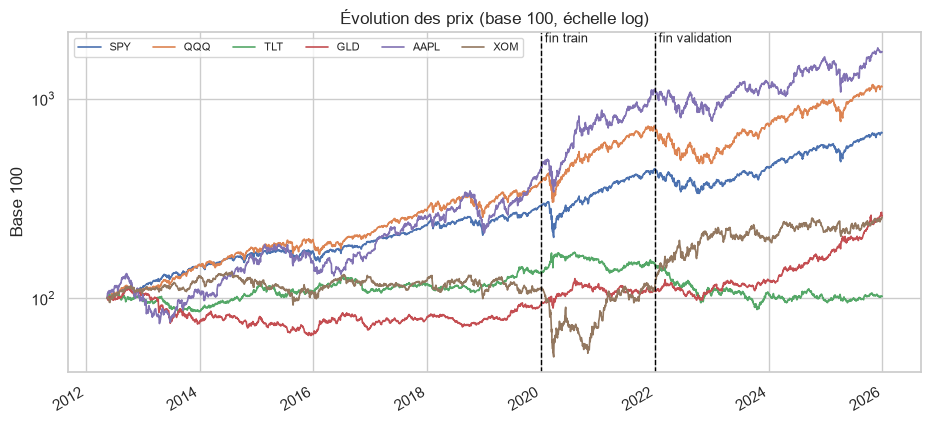

In [4]:
eda.fig_prices(prices, [train_end, val_end], FIG, cols=["SPY", "QQQ", "TLT", "GLD", "AAPL", "XOM"]);

## 2.4 Statistiques par actif (train)

Rendement et volatilité annualisés, ratio de Sharpe, asymétrie (skewness), aplatissement (kurtosis en excès : 0 pour une loi normale) et pire perte depuis un sommet (drawdown max).

In [5]:
table = eda.stats_table(returns_train)
table.to_csv(ROOT / "reports" / "stats_train.csv")
table

,rendement_annuel_%,volatilite_annuelle_%,sharpe,skewness,kurtosis_excess,drawdown_max_%
MA,27.20,21.48,1.27,-0.06,3.23,-21.86
V,25.67,20.59,1.25,0.05,4.51,-19.13
HD,22.43,18.50,1.21,-0.13,2.64,-25.61
UNH,23.90,21.23,1.13,0.03,2.66,-23.98
QQQ,17.57,16.11,1.09,-0.41,3.10,-22.80
SPY,13.99,12.89,1.09,-0.48,3.49,-19.35
MSFT,24.51,22.80,1.07,-0.16,7.91,-18.23
NVDA,40.14,37.51,1.07,0.38,15.12,-56.04
JPM,21.41,20.86,1.03,-0.05,2.67,-23.21
AMZN,28.36,29.04,0.98,0.21,8.14,-34.10


## 2.5 Distribution des rendements (train)

Les modèles classiques (Markowitz) supposent souvent des rendements normaux. On vérifie visuellement et avec le test de Jarque-Bera (p < 0,05 → on rejette la normalité).

Jarque-Bera SPY : statistique = 1042, p-value = 4.51e-227


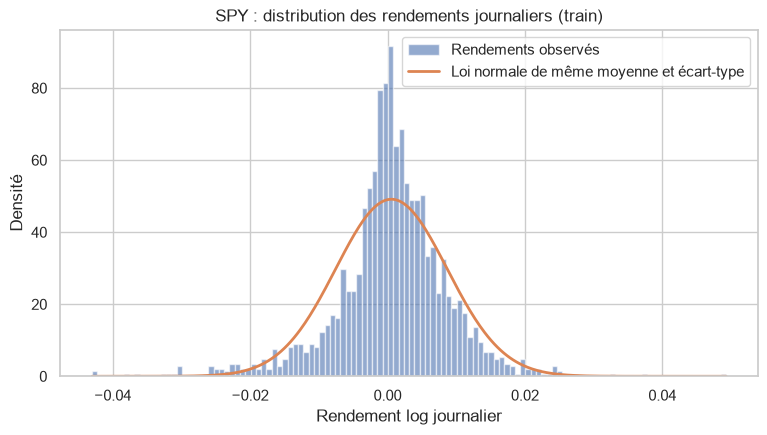

In [6]:
eda.fig_distribution(returns_train, "SPY", FIG);
jb = stats.jarque_bera(returns_train["SPY"].dropna())
print(f"Jarque-Bera SPY : statistique = {jb.statistic:.0f}, p-value = {jb.pvalue:.2e}")

## 2.6 Corrélations (train)

Les actifs sont regroupés par similarité. La diversification vient des actifs peu ou négativement corrélés (obligations TLT / IEF, or GLD).

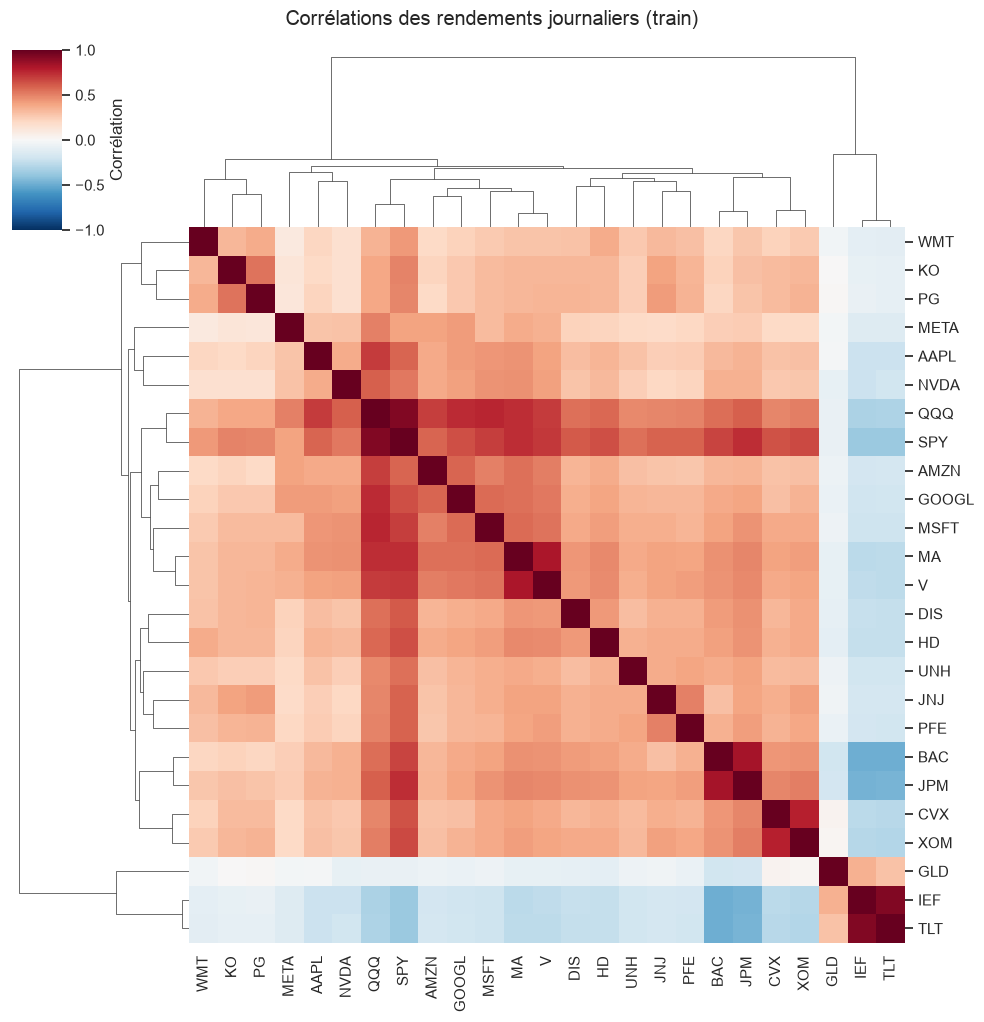

In [7]:
eda.fig_correlation(returns_train, FIG);

## 2.7 Volatilité glissante : les régimes de marché

La volatilité n'est pas constante : elle grimpe par épisodes (crises). C'est ce qui justifie un agent Risque qui adapte l'allocation au régime.

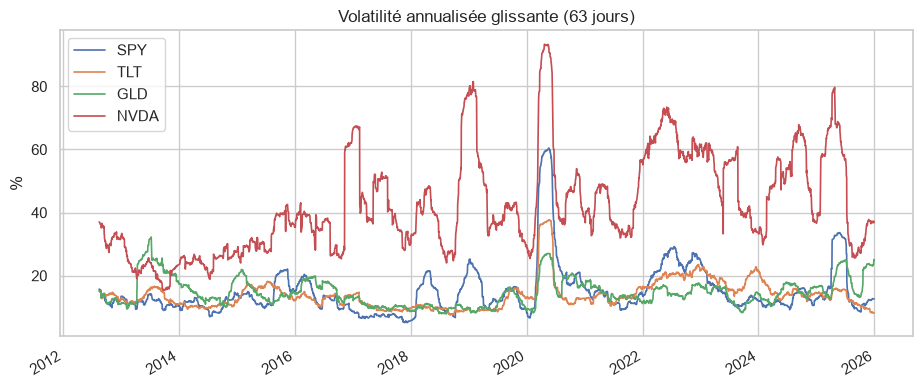

In [8]:
eda.fig_rolling_vol(returns, ["SPY", "TLT", "GLD", "NVDA"], FIG);

## 2.8 Variables macroéconomiques

Taux à 10 ans, VIX (indice de peur) et taux directeur, décalés d'un jour pour ne jamais utiliser une donnée pas encore publiée.

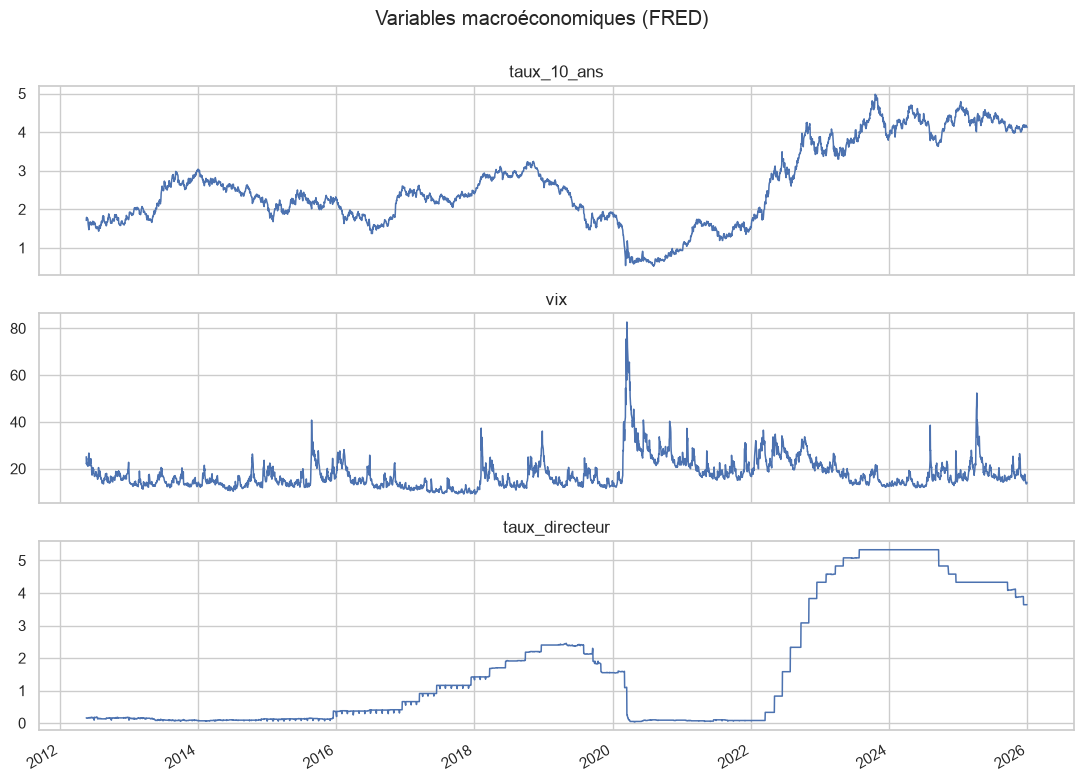

In [9]:
eda.fig_macro(macro, FIG);

## 2.9 Stationnarité (test de Dickey-Fuller augmenté, train)

Une série stationnaire garde les mêmes propriétés dans le temps, ce dont les modèles ont besoin. Attendu : les prix ne sont pas stationnaires (p > 0,05), les rendements le sont (p < 0,05). C'est pourquoi on modélise des **rendements**, pas des prix.

In [10]:
adf = eda.adf_table(prices_train, returns_train)
adf.to_csv(ROOT / "reports" / "adf_train.csv")
adf

/Users/houdie/Desktop/portfolio-multi-agent/src/eda.py:103: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "p_value_prix": adfuller(np.log(prices[col].dropna()), autolag="AIC")[1],
/Users/houdie/Desktop/portfolio-multi-agent/src/eda.py:104: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "p_value_rendements": adfuller(returns[col].dropna(), autolag="AIC")[1],
/Users/houdie/D

,p_value_prix,p_value_rendements
actif,,
AAPL,0.9810,0.0
AMZN,0.8566,0.0
BAC,0.4107,0.0
CVX,0.2872,0.0
DIS,0.3063,0.0
GLD,0.2536,0.0
GOOGL,0.5063,0.0
HD,0.4429,0.0
IEF,0.8983,0.0


## 2.10 Aperçu des features (train)

Une ligne par (date, actif). `target` = rendement log des 21 prochains jours de bourse : c'est ce que l'agent Prévision devra prédire.

In [11]:
feat_train = pd.read_csv(PROC / "features_train.csv", index_col=[0, 1], parse_dates=[0])
print(feat_train.shape)
feat_train.describe().T.round(3)

(39480, 14)


,count,mean,std,min,25%,50%,75%,max
mom_21,39480.0,0.013,0.057,-0.460,-0.018,0.013,0.044,0.475
mom_63,39480.0,0.039,0.097,-0.805,-0.016,0.038,0.094,0.733
mom_126,39480.0,0.079,0.134,-0.659,-0.001,0.075,0.153,0.942
vol_21,39480.0,0.189,0.101,0.025,0.122,0.168,0.230,1.092
vol_63,39480.0,0.195,0.088,0.030,0.136,0.181,0.238,0.815
rsi_14,39480.0,54.516,16.639,1.377,42.725,54.674,66.433,100.000
drawdown_252,39480.0,-0.064,0.070,-0.560,-0.092,-0.044,-0.014,0.000
target,39480.0,0.013,0.057,-0.460,-0.017,0.014,0.044,0.475
mkt_mom_21,39480.0,0.010,0.032,-0.117,-0.006,0.013,0.030,0.126
mkt_vol_21,39480.0,0.118,0.056,0.034,0.078,0.102,0.144,0.321


## 2.11 Conclusions à reporter dans le rapport

À compléter après exécution, à partir des résultats ci-dessus :

- **Qualité :** période commune du … au …, … valeurs manquantes traitées.
- **Rendements :** queues épaisses (kurtosis en excès de … pour SPY), normalité rejetée → justifie des mesures de risque comme la CVaR.
- **Corrélations :** actions très corrélées entre elles (≈ …), obligations et or peu corrélés → sources de diversification.
- **Régimes :** pics de volatilité en … → intérêt de l'agent Risque.
- **Stationnarité :** prix non stationnaires, rendements stationnaires → on modélise les rendements.